# IT5514 extension: breadth without selective reporting

D.V.S Sandaru Rashmika, 269182L. AI-assisted; review and defend the implementation.

The original electricity protocol and results remain frozen. NGBoost, KNN and gradient boosting are supplementary post-hoc comparisons on its already inspected holdout. Colombo rainfall is an independent task, with models refitted, a six-dekad input delay and training embargo. Its corrected 2024–2025 evaluation is retrospective because timing review followed first-pass outcome inspection. This notebook inspects the executed evidence and runs independent checks; it does not claim to retrain the models during these display cells.

To regenerate in a separate project copy with `requirements-extension.txt` installed:

```bash
python 03_code/acquire_rainfall.py
python 03_code/extension_experiments.py
python 03_code/summarize_extension.py
python 03_code/verify_extension.py
```

The rainfall download is rolling: the bundled snapshot is pinned by SHA-256. Read `02_data/rainfall/DATASET_CARD.md` for publication latency and revision limitations.

In [1]:
from pathlib import Path
import json,sys
import pandas as pd
ROOT=Path.cwd()
if ROOT.name=='04_notebooks': ROOT=ROOT.parent
assert (ROOT/'00_requirements/Extension_Protocol.json').exists()
sys.path.insert(0,str(ROOT/'03_code'))
protocol=json.loads((ROOT/'00_requirements/Extension_Protocol.json').read_text())
print(protocol['original_study_status'])
print('Independent rainfall features:',protocol['independent_dataset']['features'])

Frozen and preserved. Its 2025 dispatch holdout has already been examined; newly added model comparisons on it are supplementary post-hoc benchmarking, not a newly untouched final test. No original model is reselected from these scores.
Independent rainfall features: ['lag6_mm', 'lag7_mm', 'lag9_mm', 'lag36_mm', 'rolling3_mean_at_lag6_mm', 'rolling3_std_at_lag6_mm', 'annual_sin', 'annual_cos', 'trend_dekads']


DISPATCH


,study,model,unit,n_train,n_test,CV_MAE,MAE,RMSE,R2,MAE_skill_vs_seasonal
0,dispatch,NGBoost,MWh,659,97,1837.704121,1623.481303,2338.473636,0.598125,0.286100
1,dispatch,KNN,MWh,659,97,2150.508325,1773.798325,2458.223675,0.555912,0.220000
2,dispatch,Gradient boosting,MWh,659,97,1713.596417,1641.004733,2363.437981,0.589499,0.278394
3,dispatch,Seasonal naive,MWh,659,97,3025.287998,2274.100515,3172.516398,0.260337,0.000000


RAINFALL


,study,model,unit,n_train,n_test,CV_MAE,MAE,RMSE,R2,MAE_skill_vs_seasonal
0,rainfall,Linear regression,mm,858,72,53.986064,53.130075,66.173867,0.148088,0.205718
1,rainfall,Random forest,mm,858,72,51.518399,52.281707,64.640012,0.187124,0.218401
2,rainfall,SVR,mm,858,72,54.299372,48.173980,62.827428,0.232073,0.279811
3,rainfall,GPR,mm,858,72,53.250488,51.856768,65.490256,0.165599,0.224754
4,rainfall,NGBoost,mm,858,72,53.680900,63.085087,75.184582,-0.099713,0.056893
5,rainfall,KNN,mm,858,72,52.094872,49.471701,63.405472,0.217877,0.260410
6,rainfall,Gradient boosting,mm,858,72,54.606626,55.722364,67.360258,0.117268,0.166964
7,rainfall,Seasonal naive,mm,858,72,67.524960,66.890701,87.921653,-0.503880,0.000000
8,rainfall,Seasonal median,mm,858,72,52.255113,41.391908,58.694587,0.329780,0.381201


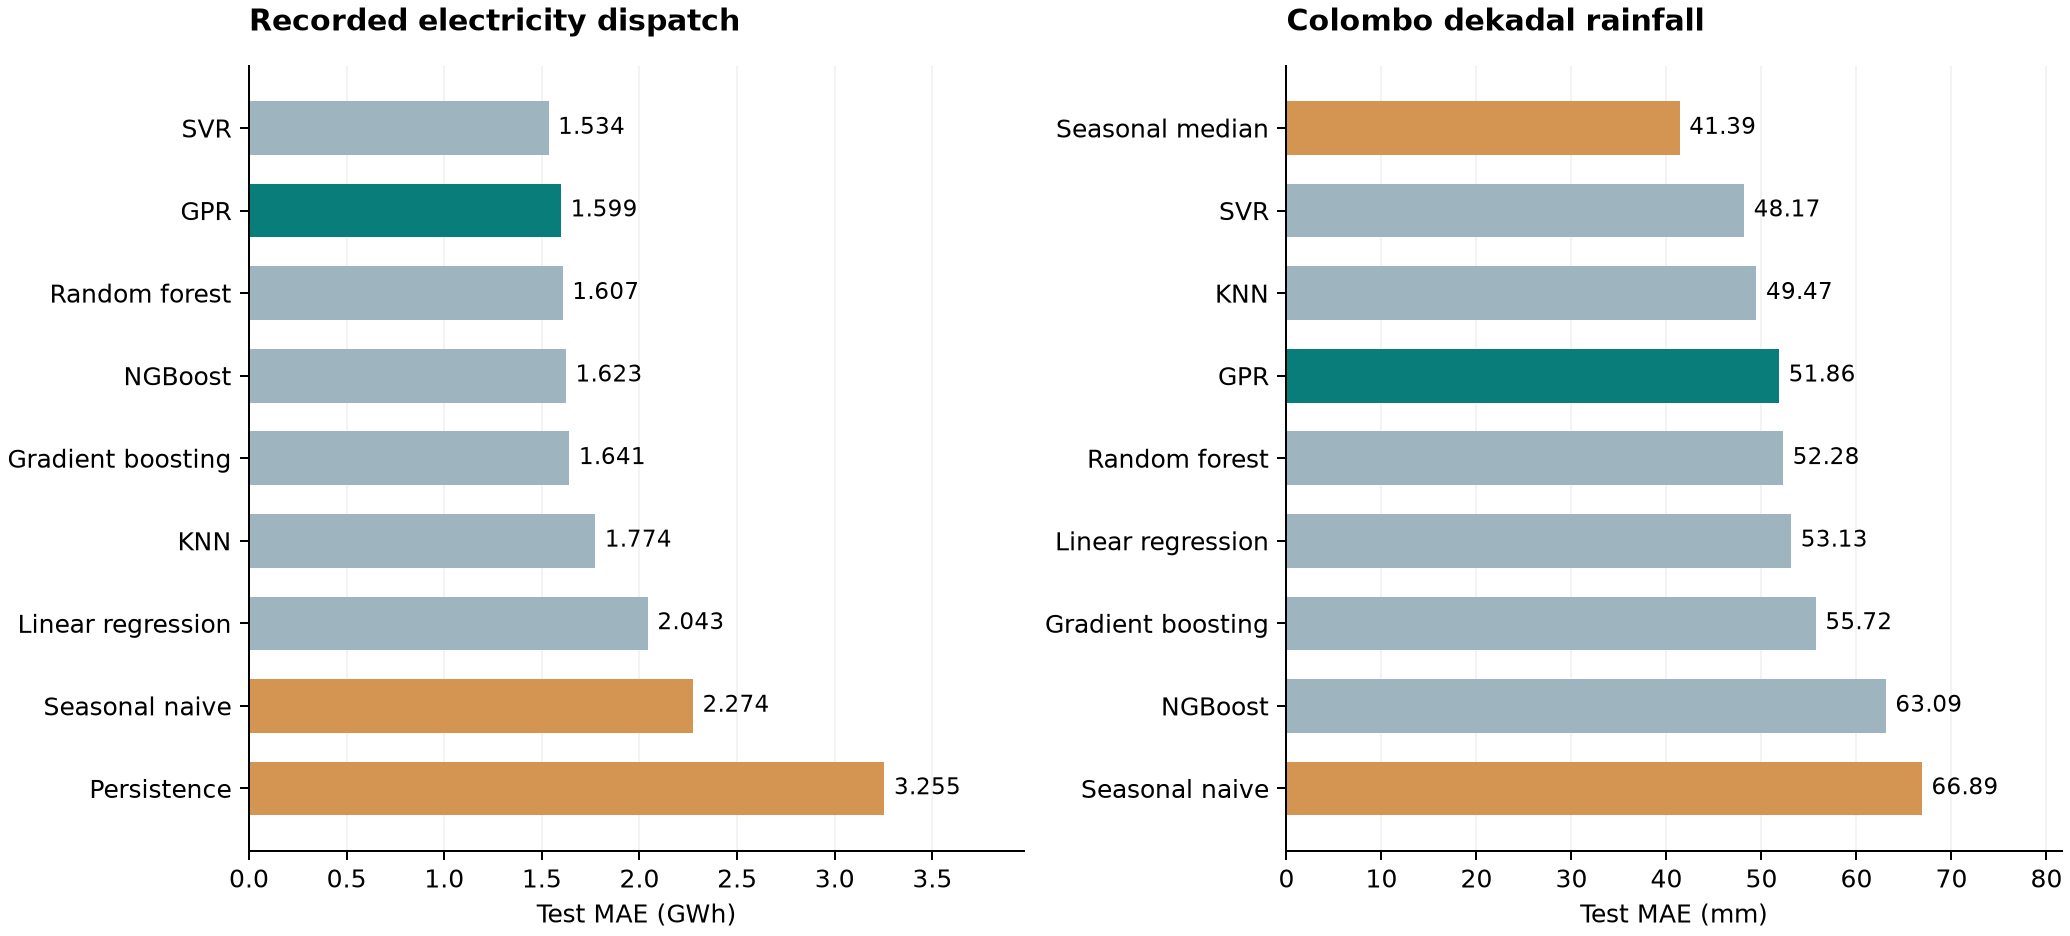

Rainfall seasonal-median test MAE is lower than every learned model. No test-driven retuning is performed.


In [2]:
from IPython.display import display,Image
for study in ['dispatch','rainfall']:
    print(study.upper())
    display(pd.read_csv(ROOT/'05_experiments/extension'/study/'test_metrics.csv').drop(columns=['fit_seconds']))
display(Image(filename=str(ROOT/'06_figures/10_extended_model_comparison.png')))
print('Rainfall seasonal-median test MAE is lower than every learned model. No test-driven retuning is performed.')

In [3]:
import subprocess
result=subprocess.run([sys.executable,str(ROOT/'03_code/verify_extension.py')],cwd=ROOT,text=True,capture_output=True,check=True)
print(result.stdout)
display(pd.read_csv(ROOT/'05_experiments/extension/rainfall/paired_bootstrap.csv'))
print('The 3- and 6-dekad block lengths assess dependence sensitivity; 72 observations limit certainty.')

{
  "passed": true,
  "checks": 78
}



,model_minus,model,block_dekads,difference_MAE_mm,CI_lower,CI_upper,bootstrap_replicates
0,Seasonal median,GPR,3,10.464860,2.307596,19.171961,2000
1,Seasonal median,GPR,6,10.464860,1.369131,20.923711,2000
2,Seasonal median,NGBoost,3,21.693179,10.656314,33.330182,2000
3,Seasonal median,NGBoost,6,21.693179,8.997636,34.338951,2000
4,Seasonal median,SVR,3,6.782071,0.289035,13.697240,2000
5,Seasonal median,SVR,6,6.782071,-0.589986,14.780148,2000


The 3- and 6-dekad block lengths assess dependence sensitivity; 72 observations limit certainty.
